#### Sparse reconstruction of the [15 × 716] LiDAR grid with a range-weighted penalty
#### Hit beams (lidar_valid_return_mask) are weighted inversely proportional to lidar_ranges_m

### 0. Required run configuration — single episode

Set CONFIG["data"]["episode_path"] to the episode folder under data/raw before running.
You may enter its ID, a repository-relative path, or its absolute folder path.
The notebook uses the matching existing data/processed/lidar_episode_v1/<ID>/episode.npz.
An empty path stops execution; an unexported episode produces a clear missing-file error.

The selected episode has healthy LiDAR, so sparse inputs are produced by synthetic
full-elevation azimuth outages (CONFIG["masking"]). The clean scan is always the target.
Training uses the first configured fraction of scans; validation uses the later scans
with a fixed, seeded outage pattern. This measures later scans of the same path,
rather than generalization to other paths.

In [ ]:
from pathlib import Path
import copy
import json
import math
import random
import sys
import numpy as np
import pandas as pd
import time
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, TensorDataset

MAX_RANGE = 7.0
N_EL, N_AZ = 15, 716
SELECTION_METRICS = ("val_loss", "val_mse", "val_outage_mse")

# Edit these explicit settings before running the notebook.
# Missing, blank, or invalid settings stop execution before data loading/training.
CONFIG = {
    "paths": {
        "repo_root": r"A:\Projects\ARES",
        "output_root": r"A:\Projects\ARES\results\sparse_reconstruction_single_episode_baseline",
    },
    "run": {"name": "Sparsity Invariant CNN", "seed": 42},
    "data": {
        # REQUIRED: episode ID, data/raw/<ID>, or absolute data/raw/<ID> folder.
        "episode_path": r"A:\Projects\ARES\data\raw\f9ab72ef-e1d7-4479-8faa-03bb5b36776c",
        "train_fraction": 0.8,
        "val_fraction": 0.2,
        "split_policy": "chronological",
        "verify_hashes": True,
    },
    "model": {
        # use_position=False -> velocity(3) + sin/cos attitude(6) = 9 state features.
        # use_position=True  -> NED position(3) + the above = 12 state features.
        "input_features": 9,
        "max_range": MAX_RANGE,
        "elevation_vectors": N_EL,
        "azimuth_vectors": N_AZ,
        "azimuth_degree": [-179.0, 179.0],   # sensor azimuth columns = linspace(lo, hi, 716)
        "degree_per_column": 0.5,
        "ring_channels": 7,                  # controller sectors (evaluation only)
        "sector_bearing_deg": [-60.0, 60.0], # body bearing span split into ring_channels sectors
        "widths": [32, 64, 96],              # sparse encoder levels; each after the first halves azimuth
        "use_position": False,
        "kernel": 7,                         # odd azimuth kernel; elevation kernel is 3
        "state_hidden": 64,                  # FiLM state-MLP hidden width
        "obstacle_width_m": 3,               # sets the angular width of synthetic outages
    },
    "masking": {
        # Each scan is hit by an outage with this probability.
        "outage_probability": 0.9,
        # Number of full-elevation azimuth outage blocks per affected scan, [min, max].
        "blocks_per_scan": [1, 2],
        # Block width = azimuth columns subtended by obstacle_width_m at a distance drawn here.
        "obstacle_distance_m": [1.0, 7.0],
        # Fixed seed for the validation outage pattern (training masks are redrawn every batch).
        "validation_seed": 1234,
    },
    "training": {
        "optimizer": "adamw",
        # weight = 1 on no-return beams, max_range / max(r, weight_floor_range_m) on hits,
        # times overestimate_weight where a hit is predicted farther than measured.
        "loss": "range_weighted_mse",
        "overestimate_weight": 4.0,
        "weight_floor_range_m": 0.5,
        "selection_metric": "val_loss",      # val_loss, val_mse or val_outage_mse
        "epochs": 500,
        "batch_size": 32,
        "learning_rate": 1e-3,
        "weight_decay": 1e-3,
        "betas": [0.9, 0.999],
        "eps": 1e-8,
        "patience": 25,
        "save_every_n_epochs": 100,
    },
    "scheduler": {
        "name": "cosine",
        "t_max_epochs": 2000,
        "min_lr": 1e-6,
    },
    "runtime": {
        "gpu_index": 0,
        "amp_dtype": "bf16",
        "num_workers": 0,
        "pin_memory": True,
        "persistent_workers": False,
        "cudnn_benchmark": True,
        "matmul_precision": "high",
        "fused_adamw": True,
    },
    "plots": {
        "dpi": 160,
        "scan_index": 0,
        "range_min_m": 0.0,
        "range_max_m": 7.0,
        "colormap": "viridis",
    },
}


def validate_config(config):
    required = {
        "paths": ("repo_root", "output_root"),
        "run": ("name", "seed"),
        "data": ("episode_path", "train_fraction", "val_fraction",
                 "split_policy", "verify_hashes"),
        "model": ("input_features", "max_range", "elevation_vectors",
                  "azimuth_vectors", "azimuth_degree", "degree_per_column",
                  "ring_channels", "sector_bearing_deg", "widths", "use_position",
                  "kernel", "state_hidden", "obstacle_width_m"),
        "masking": ("outage_probability", "blocks_per_scan", "obstacle_distance_m",
                    "validation_seed"),
        "training": ("optimizer", "loss", "overestimate_weight", "weight_floor_range_m",
                     "selection_metric", "epochs", "batch_size", "learning_rate",
                     "weight_decay", "betas", "eps", "
                     e", "save_every_n_epochs"),
        "scheduler": ("name", "t_max_epochs", "min_lr"),
        "runtime": ("gpu_index", "amp_dtype", "num_workers", "pin_memory",
                    "persistent_workers", "cudnn_benchmark", "matmul_precision",
                    "fused_adamw"),
        "plots": ("dpi", "scan_index", "range_min_m", "range_max_m", "colormap"),
    }
    for section, keys in required.items():
        if section not in config or not isinstance(config[section], dict):
            raise ValueError(f"Missing configuration section: {section}")
        for key in keys:
            if key not in config[section]:
                raise ValueError(f"Missing configuration: {section}.{key}")

    def check_filled(value, path):
        if value is None or (isinstance(value, str) and not value.strip()):
            raise ValueError(f"Fill configuration before execution: {path}")
        if isinstance(value, dict):
            for key, item in value.items():
                check_filled(item, f"{path}.{key}")
        elif isinstance(value, (list, tuple)):
            if not value:
                raise ValueError(f"Empty configuration: {path}")
            for i, item in enumerate(value):
                check_filled(item, f"{path}[{i}]")
        elif isinstance(value, float) and not math.isfinite(value):
            raise ValueError(f"Non-finite configuration: {path}")
    check_filled(config, "CONFIG")

    def integer(value, label, minimum):
        if isinstance(value, bool) or not isinstance(value, int) or value < minimum:
            raise ValueError(f"{label} must be an integer >= {minimum}.")

    def number(value, label, minimum, *, positive=False):
        if isinstance(value, bool) or not isinstance(value, (int, float)):
            raise ValueError(f"{label} must be numeric.")
        if not math.isfinite(value) or value < minimum or (positive and value == minimum):
            raise ValueError(f"Invalid numeric value: {label}")

    def ordered_pair(value, label, *, strict):
        if not isinstance(value, (list, tuple)) or len(value) != 2:
            raise ValueError(f"{label} must contain two values [low, high].")
        for item in value:
            number(item, label, -math.inf)
        if value[0] > value[1] or (strict and value[0] == value[1]):
            raise ValueError(f"{label} must be ordered [low, high].")

    for section, keys, minimum in (
        ("run", ("seed",), 0),
        ("model", ("input_features", "elevation_vectors", "azimuth_vectors",
                   "ring_channels", "state_hidden"), 1),
        ("model", ("kernel",), 3),
        ("masking", ("validation_seed",), 0),
        ("training", ("epochs", "batch_size", "patience"), 1),
        ("training", ("save_every_n_epochs",), 0),
        ("scheduler", ("t_max_epochs",), 1),
        ("runtime", ("gpu_index", "num_workers"), 0),
        ("plots", ("scan_index",), 0),
        ("plots", ("dpi",), 1),
    ):
        for key in keys:
            integer(config[section][key], f"{section}.{key}", minimum)

    d, m, k, t, s, r, p = (config[key] for key in
                            ("data", "model", "masking", "training", "scheduler",
                             "runtime", "plots"))
    for key in ("train_fraction", "val_fraction"):
        number(d[key], f"data.{key}", 0, positive=True)
    if not math.isclose(d["train_fraction"] + d["val_fraction"], 1, rel_tol=0, abs_tol=1e-12):
        raise ValueError("Train/validation fractions must sum to 1.")
    if d["split_policy"] != "chronological":
        raise ValueError("Single-episode validation uses a chronological scan split.")

    ########################################################################################

    if not isinstance(m["use_position"], bool):
        raise ValueError("model.use_position must be boolean.")
    if m["input_features"] != (12 if m["use_position"] else 9):
        raise ValueError("model.input_features must be 12 with use_position=True "
                         "(position + velocity + sin/cos attitude) or 9 without position.")
    number(m["max_range"], "model.max_range", 0, positive=True)
    if not math.isclose(m["max_range"], MAX_RANGE):
        raise ValueError("The recorded no-return range is 7 m.")
    if (m["elevation_vectors"], m["azimuth_vectors"]) != (N_EL, N_AZ):
        raise ValueError("The recorded target shape is [15, 716].")
    ordered_pair(m["azimuth_degree"], "model.azimuth_degree", strict=True)
    number(m["degree_per_column"], "model.degree_per_column", 0, positive=True)
    column_step = (m["azimuth_degree"][1] - m["azimuth_degree"][0]) / (m["azimuth_vectors"] - 1)
    if not math.isclose(m["degree_per_column"], column_step, rel_tol=0, abs_tol=0.01):
        raise ValueError(f"model.degree_per_column must match the azimuth spacing ({column_step:.4f}).")
    ordered_pair(m["sector_bearing_deg"], "model.sector_bearing_deg", strict=True)
    if not all(-180 <= value <= 180 for value in m["sector_bearing_deg"]):
        raise ValueError("model.sector_bearing_deg must lie in [-180, 180].")
    if not isinstance(m["widths"], (list, tuple)) or not m["widths"]:
        raise ValueError("model.widths must be a nonempty sequence.")
    for value in m["widths"]:
        integer(value, "model.widths", 1)
    if m["kernel"] % 2 == 0:
        raise ValueError("Use an odd model.kernel to preserve sequence lengths.")
    if m["azimuth_vectors"] % 2 ** (len(m["widths"]) - 1):
        raise ValueError("Each encoder level after the first halves azimuth; "
                         "716 must divide evenly by 2**(len(widths)-1).")
    number(m["obstacle_width_m"], "model.obstacle_width_m", 0, positive=True)

    number(k["outage_probability"], "masking.outage_probability", 0, positive=True)
    if k["outage_probability"] > 1:
        raise ValueError("masking.outage_probability must be in (0, 1].")
    ordered_pair(k["blocks_per_scan"], "masking.blocks_per_scan", strict=False)
    for value in k["blocks_per_scan"]:
        integer(value, "masking.blocks_per_scan", 1)
    ordered_pair(k["obstacle_distance_m"], "masking.obstacle_distance_m", strict=False)
    if k["obstacle_distance_m"][0] <= 0 or k["obstacle_distance_m"][1] > m["max_range"]:
        raise ValueError("masking.obstacle_distance_m must lie in (0, max_range].")

    if t["optimizer"] != "adamw" or t["loss"] != "range_weighted_mse":
        raise ValueError("This trainer uses AdamW and the range-weighted MSE loss.")
    number(t["overestimate_weight"], "training.overestimate_weight", 1)
    number(t["weight_floor_range_m"], "training.weight_floor_range_m", 0, positive=True)
    if t["selection_metric"] not in SELECTION_METRICS:
        raise ValueError(f"training.selection_metric must be one of {SELECTION_METRICS}.")

    ##########################################################################################

    for key in ("learning_rate", "eps"):
        number(t[key], f"training.{key}", 0, positive=True)
    number(t["weight_decay"], "training.weight_decay", 0)
    if not isinstance(t["betas"], (list, tuple)) or len(t["betas"]) != 2:
        raise ValueError("training.betas must contain two values.")
    for value in t["betas"]:
        number(value, "training.betas", 0)
        if value >= 1:
            raise ValueError("AdamW betas must be below 1.")
    number(s["min_lr"], "scheduler.min_lr", 0)
    if s["name"] != "cosine" or s["t_max_epochs"] < t["epochs"]:
        raise ValueError("Use cosine with t_max_epochs >= training.epochs to avoid LR rising again.")
    if s["min_lr"] >= t["learning_rate"]:
        raise ValueError("scheduler.min_lr must be below the initial learning rate.")
    for section, key in (("data", "verify_hashes"), ("runtime", "pin_memory"),
                         ("runtime", "persistent_workers"), ("runtime", "cudnn_benchmark"),
                         ("runtime", "fused_adamw")):
        if not isinstance(config[section][key], bool):
            raise ValueError(f"{section}.{key} must be boolean.")
    if r["persistent_workers"] and r["num_workers"] == 0:
        raise ValueError("persistent_workers requires num_workers > 0.")
    if r["amp_dtype"] not in ("bf16", "fp16"):
        raise ValueError("runtime.amp_dtype must be bf16 or fp16.")
    if r["matmul_precision"] not in ("highest", "high", "medium"):
        raise ValueError("Invalid runtime.matmul_precision.")
    number(p["range_min_m"], "plots.range_min_m", 0)
    number(p["range_max_m"], "plots.range_max_m", 0, positive=True)
    if p["range_max_m"] <= p["range_min_m"]:
        raise ValueError("Plot maximum must exceed minimum.")
    for section, key in (("paths", "repo_root"), ("paths", "output_root"),
                         ("run", "name"), ("data", "episode_path"), ("plots", "colormap")):
        if not isinstance(config[section][key], str):
            raise ValueError(f"{section}.{key} must be a string.")
    for label, value in (("run.name", config["run"]["name"]),):
        if value in (".", "..") or any(c in value for c in '<>:"/\\|?*'):
            raise ValueError(f"{label} must be a Windows-safe single folder name.")
    json.dumps(config, allow_nan=False)
    return config


def resolve_episode_directory(repo_root, episode_path):
    """Accept an episode ID, data/raw/<ID>, or an absolute raw episode folder."""
    root = Path(repo_root).expanduser().resolve()
    raw_root = (root / "data" / "raw").resolve()
    value = Path(episode_path).expanduser()
    if not value.is_absolute():
        value = raw_root / value if len(value.parts) == 1 else root / value
    value = value.resolve()
    if value.parent != raw_root:
        raise ValueError("Select one episode folder directly inside repo_root/data/raw.")
    return value


validate_config(CONFIG)
REPO_ROOT = Path(CONFIG["paths"]["repo_root"]).expanduser().resolve()
EPISODE_PATH = CONFIG["data"]["episode_path"]
OUTPUT_ROOT = Path(CONFIG["paths"]["output_root"]).expanduser().resolve()
AZ_DEG = np.linspace(*CONFIG["model"]["azimuth_degree"], CONFIG["model"]["azimuth_vectors"])
print("Configuration validated. Output root:", OUTPUT_ROOT)

Configuration validated. Output root: A:\Projects\ARES\results\sparse_reconstruction_single_episode_baseline


### 1. Locate the configured single episode

In [7]:
import os
import platform

PYTHON = Path(sys.executable).resolve()
EPISODE_DIR = resolve_episode_directory(REPO_ROOT, EPISODE_PATH)
NPZ_PATH = (REPO_ROOT / "data" / "processed" / "lidar_episode_v1"
            / EPISODE_DIR.name / "episode.npz")
required = [EPISODE_DIR / "manifest.json", NPZ_PATH]
missing = [str(path) for path in required if not path.is_file()]
if missing:
    raise FileNotFoundError(
        "Missing selected episode inputs: " + repr(missing)
        + ". The raw episode must have an existing lidar_episode_v1 Python export."
    )
print("Notebook kernel:", PYTHON)
print("Platform:", platform.platform())
print("Selected raw episode:", EPISODE_DIR)
print("Exported scans:", NPZ_PATH)

Notebook kernel: A:\Projects\ARES\.venv\Scripts\python.exe
Platform: Windows-10-10.0.26200-SP0
Selected raw episode: A:\Projects\ARES\data\raw\f9ab72ef-e1d7-4479-8faa-03bb5b36776c
Exported scans: A:\Projects\ARES\data\processed\lidar_episode_v1\f9ab72ef-e1d7-4479-8faa-03bb5b36776c\episode.npz


### 2. Check packages and CUDA

In [8]:
import importlib.util
from importlib.metadata import version as package_version

required_packages = ("numpy", "pandas", "torch", "matplotlib")
missing = [name for name in required_packages if importlib.util.find_spec(name) is None]
if missing:
    raise RuntimeError("Install these packages in the active notebook environment: " + repr(missing))
print({name: package_version(name) for name in required_packages})

{'numpy': '2.4.6', 'pandas': '3.1.1', 'torch': '2.11.0+cu128', 'matplotlib': '3.11.2'}


In [9]:
if tuple(int(part) for part in torch.__version__.split("+")[0].split(".")[:2]) < (2, 5):
    raise RuntimeError("This notebook requires PyTorch >= 2.5.")
if not torch.cuda.is_available():
    raise RuntimeError("CUDA is unavailable in this notebook kernel.")
if CONFIG["runtime"]["gpu_index"] >= torch.cuda.device_count():
    raise ValueError("Configured GPU index is unavailable.")
torch.cuda.set_device(CONFIG["runtime"]["gpu_index"])
if CONFIG["runtime"]["amp_dtype"] == "bf16" and not torch.cuda.is_bf16_supported():
    raise ValueError("Configured BF16 is unsupported; select fp16 explicitly.")
if CONFIG["plots"]["colormap"] not in plt.colormaps():
    raise ValueError("Unknown plots.colormap.")
print("GPU:", torch.cuda.get_device_name(CONFIG["runtime"]["gpu_index"]))
print("AMP:", CONFIG["runtime"]["amp_dtype"])

GPU: NVIDIA GeForce RTX 4080 Laptop GPU
AMP: bf16


### 3. Model, state encoding, synthetic outages and loss

**Input** per scan: measured ranges, valid-return mask and availability mask, all [15, 716],
plus the encoded state (9 features without position: vN, vE, vD, sin/cos roll, pitch, yaw).
Two image channels enter the sparse encoder: *nearness* `1 − r/7` (0 on no-return beams)
and a *hit* indicator. The availability mask is the sparse support, so measured free space
counts as evidence while outage beams carry none.

**Sparse encoder** — sparsity-invariant convolutions (Uhrig et al., 3DV 2017):
`y = W∗(x⊙m) / (Σ_window m + ε) + b`, `m_out = maxpool(m)`. Azimuth is padded circularly
(the scan wraps at ±179°), elevation with zeros. Kernel `(3, kernel)`; one level per entry
of `widths`, each level after the first halves azimuth: 716 → 358 → 179.

**FiLM** — a state MLP (`state_hidden`) scales and shifts the bottleneck features, so the
vehicle's motion and attitude can inform what lies inside an outage. It starts as identity.

**Dense decoder** — nearest ×2 upsampling with U-Net skips; every stage also sees the support
mask so it knows which beams it is inventing. The head sees the raw input channels and
returns `7·sigmoid(·)`, a dense [15, 716] range grid computed in float32.

**Synthetic outages** — the episode's LiDAR is healthy, so outage blocks are drawn as
full-elevation azimuth spans. Block width is the angle subtended by an `obstacle_width_m`
object at a distance drawn from `masking.obstacle_distance_m`, converted with
`degree_per_column`. Hidden beams are removed from the input; the clean scan is the target.

**Loss** — range-weighted MSE. No-return beams have weight 1; valid hits weight
`7 / max(r, weight_floor_range_m)`, so a hit at 1 m counts 7× a free beam. Hits predicted
farther than measured (the unsafe direction) are multiplied by `overestimate_weight`.
The loss is normalized by the base weights, keeping it on an MSE (m²) scale.

The 7 controller-sector minimums (`ring_channels` over `sector_bearing_deg`, body bearing =
−sensor azimuth) are derived from the predicted grid and logged as `val_sector_mae`.

In [10]:
###################################################################
## PRE-PROCESSING FUNCTION
###################################################################
def encode_sensor_state(raw_states, use_position):
    """[..., 9] raw (north, east, down, vn, ve, vd, roll, pitch, yaw) -> 12 or 9 features."""
    if raw_states.ndim < 1 or raw_states.shape[-1] != 9:
        raise ValueError(
            "Expected raw sensor states with last dimension 9."
        )

    raw_states = raw_states.float()
    angles = raw_states[..., 6:9]

    angle_features = torch.stack((torch.sin(angles), torch.cos(angles)), dim=-1)
    angle_features = angle_features.flatten(start_dim=-2)

    linear = raw_states[..., :6] if use_position else raw_states[..., 3:6]
    return torch.cat((linear, angle_features), dim=-1)

In [11]:
def pad_ring(tensor, pad_elevation, pad_azimuth):
    """Circular padding in azimuth (scan wraps at +/-179 deg), zero padding in elevation."""
    tensor = F.pad(tensor, (pad_azimuth, pad_azimuth, 0, 0), mode="circular")
    return F.pad(tensor, (0, 0, pad_elevation, pad_elevation), mode="constant", value=0.0)


class SparseConv2d(nn.Module):
    """Sparsity-invariant convolution: y = W*(x.m) / (sum_window m + eps) + b, m_out = maxpool(m)."""
    def __init__(self, in_channels, out_channels, kernel, stride=(1, 1)):
        super().__init__()
        self.kernel, self.stride = tuple(kernel), tuple(stride)
        self.conv = nn.Conv2d(in_channels, out_channels, self.kernel, self.stride,
                              padding=0, bias=False)
        self.bias = nn.Parameter(torch.zeros(out_channels))
        self.register_buffer("ones", torch.ones(1, 1, *self.kernel), persistent=False)
        self.pool = nn.MaxPool2d(self.kernel, self.stride)

    def forward(self, x, mask):
        pad_el, pad_az = self.kernel[0] // 2, self.kernel[1] // 2
        masked, padded_mask = pad_ring(x * mask, pad_el, pad_az), pad_ring(mask, pad_el, pad_az)
        y = self.conv(masked)
        support = F.conv2d(padded_mask, self.ones.to(padded_mask.dtype), stride=self.stride)
        y = y / support.clamp_min(1e-6) + self.bias.view(1, -1, 1, 1)
        mask_out = self.pool(padded_mask)
        return F.relu(y) * mask_out, mask_out      # zero features where still unsupported


class RingConv2d(nn.Module):
    """Dense convolution with the same ring padding; the decoder uses it to fill holes."""
    def __init__(self, in_channels, out_channels, kernel):
        super().__init__()
        self.kernel = tuple(kernel)
        self.conv = nn.Conv2d(in_channels, out_channels, self.kernel)

    def forward(self, x):
        return self.conv(pad_ring(x, self.kernel[0] // 2, self.kernel[1] // 2))

In [12]:
class SparseRangeReconstructor(nn.Module):
    """Masked [batch, 15, 716] scan + encoded state -> dense [batch, 15, 716] ranges."""
    def __init__(self, model_config):
        super().__init__()
        self.model_config = copy.deepcopy(model_config)
        c = self.model_config
        self.max_range = float(c["max_range"])
        widths = list(c["widths"])
        kernel = (3, c["kernel"])

        ############################################################################
        # Sparse encoder: two sparse convolutions per level; levels after the first
        # halve azimuth with stride (1, 2).
        self.encoder = nn.ModuleList()
        in_channels = 2                              # nearness, hit indicator
        for level, width in enumerate(widths):
            stride = (1, 1) if level == 0 else (1, 2)
            self.encoder.append(nn.ModuleList([
                SparseConv2d(in_channels, width, kernel, stride),
                SparseConv2d(width, width, kernel),
            ]))
            in_channels = width

        ############################################################################
        # FiLM state conditioning of the bottleneck, initialized as identity.
        self.film = nn.Sequential(
            nn.Linear(c["input_features"], c["state_hidden"]), nn.ReLU(),
            nn.Linear(c["state_hidden"], 2 * widths[-1]),
        )
        nn.init.zeros_(self.film[-1].weight)
        nn.init.zeros_(self.film[-1].bias)

        ############################################################################
        # Dense decoder: upsample x2, concatenate skip features and support masks.
        self.decoder = nn.ModuleList()
        for level in range(len(widths) - 1, 0, -1):
            in_channels = widths[level] + 1 + widths[level - 1] + 1
            self.decoder.append(nn.Sequential(
                RingConv2d(in_channels, widths[level - 1], kernel), nn.ReLU(),
                RingConv2d(widths[level - 1], widths[level - 1], kernel), nn.ReLU(),
            ))
        # Head sees decoder features, their support mask and the 3 raw input channels.
        self.head = nn.Conv2d(widths[0] + 1 + 3, 1, kernel_size=1)

    def forward(self, ranges, valid, available, state):
        """ranges [B,15,716] m; valid/available [B,15,716] bool; state [B, input_features]."""
        support = available.float().unsqueeze(1)
        hit = (valid & available).float().unsqueeze(1)
        nearness = (1.0 - ranges.float().unsqueeze(1) / self.max_range).clamp(0, 1) * hit
        inputs = torch.cat((nearness, hit, support), dim=1)

        x, mask = inputs[:, :2], support
        skips = []
        for first, second in self.encoder:
            x, mask = first(x, mask)
            x, mask = second(x, mask)
            skips.append((x, mask))

        gamma, beta = self.film(state)[..., None, None].chunk(2, dim=1)
        x = x * (1 + gamma) + beta

        for block, (skip_x, skip_mask) in zip(self.decoder, reversed(skips[:-1])):
            x = torch.cat((x, mask), dim=1).repeat_interleave(2, dim=-1)
            x = block(torch.cat((x, skip_x, skip_mask), dim=1))
            mask = skip_mask

        features = torch.cat((x, mask, inputs), dim=1)
        with torch.autocast(features.device.type, enabled=False):
            logits = self.head(features.float())
        return self.max_range * torch.sigmoid(logits.squeeze(1))

In [13]:
def azimuth_columns_deg(model_config):
    return np.linspace(*model_config["azimuth_degree"], model_config["azimuth_vectors"])


def sector_membership(model_config):
    """[ring_channels, 716] bool; body bearing = -sensor azimuth (roll-180 deg mount)."""
    bearing = -azimuth_columns_deg(model_config)
    edges = np.linspace(*model_config["sector_bearing_deg"], model_config["ring_channels"] + 1)
    member = np.stack([(bearing >= lo) & (bearing < hi) for lo, hi in zip(edges[:-1], edges[1:])])
    if not member.any(axis=1).all():
        raise ValueError("Every controller sector needs at least one azimuth column.")
    return torch.from_numpy(member)


def sector_min_ranges(grid, member, max_range):
    """[B, 15, 716] ranges -> [B, ring_channels] minimum range inside each sector."""
    column_min = grid.amin(dim=1).unsqueeze(1)                    # [B, 1, 716]
    inside = torch.where(member.to(grid.device).unsqueeze(0), column_min,
                         torch.full_like(column_min, max_range))
    return inside.amin(dim=-1)


def obstacle_block_columns(model_config, distance_m):
    """Azimuth columns subtended by an obstacle_width_m object at distance_m."""
    angle = 2 * torch.atan(model_config["obstacle_width_m"] / (2 * distance_m))
    columns = torch.round(torch.rad2deg(angle) / model_config["degree_per_column"])
    return columns.long().clamp(1, model_config["azimuth_vectors"])


def sample_outage_availability(batch_size, model_config, masking_config, *, generator, device):
    """[B, 15, 716] availability (False = beam lost) from full-elevation azimuth outages."""
    n_el, n_az = model_config["elevation_vectors"], model_config["azimuth_vectors"]
    low, high = masking_config["blocks_per_scan"]
    d_low, d_high = masking_config["obstacle_distance_m"]
    affected = torch.rand(batch_size, generator=generator, device=device) \
        < masking_config["outage_probability"]
    count = torch.randint(low, high + 1, (batch_size,), generator=generator, device=device)
    active = (torch.arange(high, device=device) < count.unsqueeze(1)) & affected.unsqueeze(1)
    distance = d_low + (d_high - d_low) * torch.rand(batch_size, high, generator=generator,
                                                     device=device)
    width = obstacle_block_columns(model_config, distance)                 # [B, blocks]
    start = torch.randint(0, n_az, (batch_size, high), generator=generator, device=device)
    offset = (torch.arange(n_az, device=device).view(1, 1, -1) - start.unsqueeze(-1)) % n_az
    lost = ((offset < width.unsqueeze(-1)) & active.unsqueeze(-1)).any(dim=1)   # [B, 716]
    return (~lost).unsqueeze(1).expand(batch_size, n_el, n_az).contiguous()


def apply_outage(scans, valid, available):
    """Remove hidden beams from the model input; the clean scan stays the target."""
    return scans.masked_fill(~available, 0.0), valid & available


def range_weighted_terms(prediction, target, valid, *, max_range, floor_m, overestimate_weight):
    """Numerator and base-weight denominator of the range-weighted MSE."""
    prediction = prediction.float()
    base = torch.where(valid, max_range / target.clamp_min(floor_m), torch.ones_like(target))
    weight = torch.where(valid & (prediction > target), base * overestimate_weight, base)
    return (weight * (prediction - target).square()).sum(), base.sum()


def range_weighted_mse(prediction, target, valid, **options):
    numerator, denominator = range_weighted_terms(prediction, target, valid, **options)
    return numerator / denominator

In [14]:
# Verify the complete raw-state -> encoding -> masked scan -> reconstruction path.
check_device = torch.device("cuda", CONFIG["runtime"]["gpu_index"])
with torch.inference_mode():
    check_model = SparseRangeReconstructor(CONFIG["model"]).to(check_device)
    check_generator = torch.Generator(device=check_device).manual_seed(0)
    check_available = sample_outage_availability(
        2, CONFIG["model"], CONFIG["masking"], generator=check_generator, device=check_device)
    check_ranges = torch.full((2, N_EL, N_AZ), MAX_RANGE, device=check_device)
    check_valid = torch.zeros_like(check_available)
    check_state = encode_sensor_state(torch.zeros(2, 9, device=check_device),
                                      CONFIG["model"]["use_position"])
    assert check_state.shape == (2, CONFIG["model"]["input_features"])
    check_output = check_model(*apply_outage(check_ranges, check_valid, check_available),
                               check_available, check_state)
    assert check_output.shape == (2, 15, 716)
    print("Verified model output:", tuple(check_output.shape))
    print("Trainable parameters:", sum(p.numel() for p in check_model.parameters()))
    print("Outage block columns at 2 m / 7 m:", obstacle_block_columns(
        CONFIG["model"], torch.tensor([2.0, 7.0])).tolist())
    print("Sector columns:", sector_membership(CONFIG["model"]).sum(1).tolist())
del check_model, check_generator, check_available, check_ranges, check_valid, check_state, check_output

Verified model output: (2, 15, 716)
Trainable parameters: 879269
Outage block columns at 2 m / 7 m: [147, 48]
Sector columns: [34, 35, 34, 34, 34, 35, 34]


In [15]:
import csv
import logging
import os
from datetime import datetime, timezone
from time import perf_counter
from uuid import uuid4
from matplotlib.ticker import MaxNLocator


def seed_training(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def write_json(path, value, retries=10, delay=0.05):
    path = Path(path)
    temporary = path.with_name(path.name + ".tmp")
    payload = json.dumps(value, indent=2, allow_nan=False)
    for attempt in range(retries):
        try:
            temporary.write_text(payload, encoding="utf-8")
            os.replace(temporary, path)
            break
        except PermissionError:
            if attempt == retries - 1:
                raise
            time.sleep(delay * (attempt + 1))
        finally:
            try:
                temporary.unlink(missing_ok=True)
            except PermissionError:
                pass


def save_checkpoint(path, checkpoint):
    path = Path(path)
    temporary = path.with_name(path.name + ".tmp")
    try:
        torch.save(checkpoint, temporary)
        os.replace(temporary, path)
    finally:
        temporary.unlink(missing_ok=True)


def create_training_logger(log_file):
    logger = logging.Logger("sparse_reconstruction", level=logging.INFO)
    logger.propagate = False
    formatter = logging.Formatter(
        "%(asctime)s | %(levelname)s | %(message)s", datefmt="%H:%M:%S"
    )
    for handler in (
        logging.StreamHandler(sys.stdout),
        logging.FileHandler(log_file, encoding="utf-8"),
    ):
        handler.setFormatter(formatter)
        logger.addHandler(handler)
    return logger


def log_epoch(logger, *, epoch, epochs, row, selection_metric, improved, stale_epochs, patience):
    status = "BEST" if improved else f"stale={stale_epochs}/{patience}"
    logger.info(
        "epoch=%04d/%04d | train_loss=%.5f | val_loss=%.5f | val_rmse=%.4f | "
        "outage_rmse=%.4f | outage_mae=%.4f | sector_mae=%.4f | lr=%.2e | %.1fs | %s (%s)",
        epoch, epochs, row["train_loss"], row["val_loss"], row["val_rmse"],
        row["val_outage_rmse"], row["val_outage_mae"], row["val_sector_mae"],
        row["learning_rate"], row["elapsed_s"], status, selection_metric,
    )


def plot_run_history(run_dir, *, show):
    """Read persisted metrics; works after restarting the notebook kernel."""
    run_dir = Path(run_dir)
    config = json.loads((run_dir / "config.json").read_text(encoding="utf-8"))
    history = json.loads((run_dir / "metrics.json").read_text(encoding="utf-8"))
    if not history["epoch"]:
        raise ValueError("This run has no completed epochs to plot.")
    plots = run_dir / "plots"
    plots.mkdir(exist_ok=True)
    metric = config["training"]["selection_metric"]
    best_epoch = history["epoch"][int(np.argmin(history[metric]))]

    fig, axes = plt.subplots(1, 3, figsize=(18, 4), constrained_layout=True)
    for ax, series, title, ylabel, log_scale in (
        (axes[0], (("train_loss", "Train"), ("val_loss", "Validation")),
         "Range-weighted loss", "Weighted MSE (m²)", True),
        (axes[1], (("train_rmse", "Train (all beams)"), ("val_rmse", "Validation (all beams)"),
                   ("val_outage_rmse", "Validation (outage beams)")),
         "Range error", "RMSE (m)", True),
        (axes[2], (("val_outage_mae", "Outage beams"), ("val_hit_mae", "Valid-return beams"),
                   ("val_sector_mae", "Sector minimum")),
         "Validation absolute error", "MAE (m)", True),
    ):
        for key, label in series:
            ax.plot(history["epoch"], history[key], label=label)
        ax.axvline(best_epoch, color="gray", linestyle="--",
                   label=f"Best {metric}: epoch {best_epoch}")
        ax.set(title=title, xlabel="Epoch", ylabel=ylabel)
        if log_scale:
            ax.set_yscale("log")
        ax.grid(alpha=0.25, which="both")
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))
        ax.legend()
    fig.savefig(plots / "loss_curves.png", dpi=config["plots"]["dpi"])
    if show:
        plt.show()
    plt.close(fig)

    fig, ax = plt.subplots(figsize=(7, 3), constrained_layout=True)
    ax.plot(history["epoch"], history["learning_rate"], label="LR used for epoch")
    ax.set(title="Cosine learning-rate schedule", xlabel="Epoch", ylabel="Learning rate")
    ax.grid(alpha=0.25)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.legend()
    fig.savefig(plots / "learning_rate.png", dpi=config["plots"]["dpi"])
    if show:
        plt.show()
    plt.close(fig)


def plot_validation_example(model, val_data, run_dir, *, show):
    """Compare a measured scan, its masked input and the best model's reconstruction."""
    run_dir = Path(run_dir)
    config = json.loads((run_dir / "config.json").read_text(encoding="utf-8"))
    p, m = config["plots"], config["model"]
    index = p["scan_index"]
    if index >= len(val_data):
        raise ValueError("plots.scan_index exceeds the validation dataset.")
    state, target, valid, available = val_data[index]
    device = next(model.parameters()).device
    amp_dtype = torch.bfloat16 if config["runtime"]["amp_dtype"] == "bf16" else torch.float16
    model.eval()
    with torch.inference_mode(), torch.autocast(device.type, dtype=amp_dtype):
        batch = [t.unsqueeze(0).to(device) for t in (target, valid, available)]
        encoded = encode_sensor_state(state.unsqueeze(0).to(device, dtype=torch.float32),
                                      m["use_position"])
        prediction = model(*apply_outage(*batch), batch[2], encoded)
    member = sector_membership(m)
    predicted_sectors = sector_min_ranges(prediction.float(), member, m["max_range"])[0].cpu().numpy()
    target_sectors = sector_min_ranges(batch[0].float(), member, m["max_range"])[0].cpu().numpy()
    prediction = prediction[0].float().cpu().numpy()
    measured = target.numpy()
    lost = ~available.numpy()
    error = np.abs(prediction - measured)
    outage_mae = float(error[lost].mean()) if lost.any() else float("nan")

    cmap = plt.get_cmap(p["colormap"]).copy()
    cmap.set_bad("0.85")
    fig, axes = plt.subplot_mosaic(
        [["measured", "input"], ["prediction", "error"], ["sectors", "sectors"]],
        figsize=(16, 11), constrained_layout=True,
        gridspec_kw={"height_ratios": [1, 1, 0.8]})
    range_kwargs = dict(vmin=p["range_min_m"], vmax=p["range_max_m"], cmap=cmap)
    for key, values, title, kwargs in (
        ("measured", measured, "Measured range (target)", range_kwargs),
        ("input", np.ma.masked_where(lost, measured), "Model input (gray = outage)", range_kwargs),
        ("prediction", prediction, "Reconstructed range (best checkpoint)", range_kwargs),
        ("error", error, "Absolute range error (white = outage boundary)",
         dict(vmin=0, vmax=max(float(error.max()), 1e-9), cmap=p["colormap"])),
    ):
        ax = axes[key]
        im = ax.imshow(values, aspect="auto", origin="lower", **kwargs)
        if key == "error" and lost.any():
            ax.contour(lost.astype(float), levels=[0.5], colors="white", linewidths=0.8)
        ax.set(title=title, xlabel="Azimuth bin", ylabel="Elevation bin")
        fig.colorbar(im, ax=ax, label="Meters")

    edges = np.linspace(*m["sector_bearing_deg"], m["ring_channels"] + 1)
    labels = [f"{lo:+.0f}..{hi:+.0f}°" for lo, hi in zip(edges[:-1], edges[1:])]
    positions = np.arange(m["ring_channels"])
    ax = axes["sectors"]
    ax.bar(positions - 0.2, target_sectors, width=0.4, label="Measured")
    ax.bar(positions + 0.2, predicted_sectors, width=0.4, label="Reconstructed")
    ax.set_xticks(positions, labels)
    ax.set(title="Controller sector minimum range (body bearing)", ylabel="Meters",
           ylim=(0, m["max_range"] * 1.05))
    ax.grid(alpha=0.25, axis="y")
    ax.legend()
    fig.suptitle(f"Validation sample {index} | MAE = {error.mean():.4f} m | "
                 f"outage MAE = {outage_mae:.4f} m | outage beams = {lost.mean():.1%}")
    plots = run_dir / "plots"
    plots.mkdir(exist_ok=True)
    fig.savefig(plots / "validation_scan.png", dpi=p["dpi"])
    if show:
        plt.show()
    plt.close(fig)

### 4. Saved output for each run

In [16]:
print("Output root:", OUTPUT_ROOT)
print("Each run gets a new folder containing config.json, source.json, splits.json, training.log,")
print("metrics.csv, metrics.json, summary.json, validation_outages.npz, best.pt, last.pt, and plots/.")

Output root: A:\Projects\ARES\results\sparse_reconstruction_single_episode_baseline
Each run gets a new folder containing config.json, source.json, splits.json, training.log,
metrics.csv, metrics.json, summary.json, validation_outages.npz, best.pt, last.pt, and plots/.


### 5. Load one episode and freeze chronological scan folds

Only the selected episode is loaded. Training uses its earlier scans and validation
uses its later scans. The scan IDs and timestamps stay disjoint; training batches
are shuffled only after the split. The valid-return mask is kept alongside the ranges
because it drives the loss weights (a hit at exactly 7 m is still a hit).
With checksum verification enabled, the matching export audit is located automatically.

In [17]:
import hashlib
from types import SimpleNamespace


def file_sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


def build_dataset(repo_root, episode_path, train_fraction, val_fraction, *,
                  split_policy, verify_hashes):
    """Load only the selected episode and freeze disjoint chronological scan folds."""
    root = Path(repo_root).expanduser().resolve()
    episode_dir = resolve_episode_directory(root, episode_path)
    manifest_path = episode_dir / "manifest.json"
    if not manifest_path.is_file():
        raise FileNotFoundError(f"Missing raw episode manifest: {manifest_path}")
    manifest = json.loads(manifest_path.read_text(encoding="utf-8-sig"))
    episode_id = episode_dir.name
    if str(manifest["runId"]) != episode_id:
        raise ValueError("The raw folder name differs from the manifest episode ID.")
    if split_policy != "chronological":
        raise ValueError("This single-path notebook uses a chronological scan split.")
    if not (math.isfinite(train_fraction) and math.isfinite(val_fraction)
            and train_fraction > 0 and val_fraction > 0
            and math.isclose(train_fraction + val_fraction, 1, rel_tol=0, abs_tol=1e-12)):
        raise ValueError("Positive train/validation fractions must sum to one.")

    # The raw folder supplies identity; the existing Python export supplies aligned scans.
    npz_path = root / "data" / "processed" / "lidar_episode_v1" / episode_id / "episode.npz"
    if not npz_path.is_file():
        raise FileNotFoundError(
            f"No Python export for selected raw episode: {npz_path}. "
            "Export this episode to the existing lidar_episode_v1 format first."
        )
    npz_sha256 = file_sha256(npz_path)
    report_path = None
    expected_count = None
    if verify_hashes:
        matches = []
        for candidate in sorted((root / "data" / "batches").glob("*/python_export_qa.json")):
            report = json.loads(candidate.read_text(encoding="utf-8-sig"))
            entries = [item for item in report.get("files", []) if item["runId"] == episode_id]
            if entries:
                if report.get("allExportChecksPassed") is not True:
                    raise ValueError(f"Selected episode's export audit did not pass: {candidate}")
                matches.extend((candidate, entry) for entry in entries)
        if not matches:
            raise ValueError(
                "No export checksum report found for this episode. Supply its export audit "
                "or explicitly set data.verify_hashes=False for an unaudited export.")

        if any(entry["npzSha256"] != npz_sha256 for _, entry in matches):
            raise ValueError("Selected episode's NPZ checksum differs from its export report.")

        if len({int(entry["scanCount"]) for _, entry in matches}) != 1:
            raise ValueError("Export reports disagree on this episode's scan count.")
        report_path, entry = matches[0]
        expected_count = int(entry["scanCount"])

    fields = ("time_s", "sample_index", "position_ned_m", "velocity_ned_mps",
              "attitude_ned_rpy_rad", "lidar_ranges_m", "lidar_valid_return_mask",
              "lidar_availability_mask", "lidar_missing_mask", "lidar_enabled")

    with np.load(npz_path, allow_pickle=False) as archive:
        required = set(fields) | {"run_id", "schema_version", "metadata_json"}
        if not required.issubset(archive.files):
            raise ValueError(f"Selected NPZ is missing fields: {required - set(archive.files)}")
        if (str(archive["run_id"].item()) != episode_id
                or str(archive["schema_version"].item()) != "ares-python-lidar-episode-v1"):
            raise ValueError("Selected NPZ episode identity or schema is invalid.")
        export_metadata = json.loads(str(archive["metadata_json"].item()))
        if (export_metadata["lidar_grid_size"] != [15, 716]
                or export_metadata["lidar_channel_order"] !=
                "elevation-index-fastest-then-azimuth-index"):
            raise ValueError("Selected episode has incompatible LiDAR beam ordering.")
        episode = {name: archive[name] for name in fields}

    times = np.asarray(episode["time_s"], dtype=np.float64)
    count = len(times)
    if count < 2 or times.shape != (count,) or not np.isfinite(times).all():
        raise ValueError("An episode needs at least two finite timestamps.")

    if not np.allclose(np.diff(times), 0.1, rtol=0, atol=1e-6):
        raise ValueError("Expected strictly increasing, aligned 10 Hz scan timestamps.")

    if expected_count is not None and count != expected_count:
        raise ValueError("Episode scan count differs from its export report.")

    if not np.array_equal(episode["sample_index"], np.arange(1, count + 1)):
        raise ValueError("Episode sample indices must be contiguous and one-based.")

    for field in ("position_ned_m", "velocity_ned_mps", "attitude_ned_rpy_rad"):
        if episode[field].shape != (count, 3) or not np.isfinite(episode[field]).all():
            raise ValueError(f"Invalid state array: {field}")
    ranges = episode["lidar_ranges_m"]
    if ranges.shape != (count, 15 * 716) or not np.isfinite(ranges).all():
        raise ValueError("Expected finite full-resolution [T, 10740] ranges.")
    for field in ("lidar_valid_return_mask", "lidar_availability_mask", "lidar_missing_mask"):
        if episode[field].shape != ranges.shape or not np.isin(episode[field], [0, 1]).all():
            raise ValueError(f"Invalid LiDAR mask: {field}")
    if (episode["lidar_enabled"].shape != (count,)
            or not np.equal(episode["lidar_enabled"], True).all()
            or not episode["lidar_availability_mask"].all()
            or episode["lidar_missing_mask"].any()):
        raise ValueError("Selected episode must contain measured, healthy LiDAR "
                         "(outages are synthesized by CONFIG['masking']).")
    maximum = float(manifest["static"]["maximum_sensor_range_m"])
    valid = episode["lidar_valid_return_mask"].astype(bool)
    if (not math.isclose(maximum, MAX_RANGE) or not ((ranges >= 0) & (ranges <= maximum)).all()
            or not (ranges[valid] > 0).all() or not (ranges[~valid] == maximum).all()):
        raise ValueError("Invalid recorded range or no-return encoding.")

    states = np.column_stack((
        episode["position_ned_m"], episode["velocity_ned_mps"],
        episode["attitude_ned_rpy_rad"],
    )).astype(np.float32, copy=False)
    scans = ranges.reshape(count, 716, 15).transpose(0, 2, 1).astype(np.float32, copy=False)
    valid_grid = valid.reshape(count, 716, 15).transpose(0, 2, 1)
    boundary = int(math.floor(count * train_fraction))
    if boundary < 1 or boundary >= count:
        raise ValueError("The chosen fractions leave an empty train or validation fold.")

    split_ranges = {"train": [0, boundary], "validation": [boundary, count]}
    splits = {
        name: [f"{episode_id}:{index + 1}" for index in range(start, stop)]
        for name, (start, stop) in split_ranges.items()
    }

    source_metadata = {
        "episode_id": episode_id, "episode_path": str(episode_dir),
        "npz_path": str(npz_path), "npz_sha256": npz_sha256,
        "manifest_sha256": file_sha256(manifest_path),
        "checksum_verified": verify_hashes,
        "checksum_report": str(report_path) if report_path is not None else None,
        "split_policy": split_policy, "total_scans": count,
        "split_ranges_zero_based_end_exclusive": split_ranges,
        "valid_return_fraction": float(valid.mean()),
        "validation_scope": "later scans of the same path with synthetic outages; "
                            "not unseen-path or real-outage evaluation",
    }
    return SimpleNamespace(
        episode_id=episode_id, states=states, scans=scans, valid=valid_grid, times=times,
        splits=splits, split_ranges=split_ranges, source_metadata=source_metadata,
        diagnostics={name: {
            "scan_count": stop - start,
            "first_time_s": float(times[start]), "last_time_s": float(times[stop - 1]),
            "valid_return_fraction": float(valid_grid[start:stop].mean()),
        } for name, (start, stop) in split_ranges.items()},
    )

In [18]:
validate_config(CONFIG)
d = CONFIG["data"]
corpus = build_dataset(
    REPO_ROOT, episode_path=d["episode_path"],
    train_fraction=d["train_fraction"], val_fraction=d["val_fraction"],
    split_policy=d["split_policy"], verify_hashes=d["verify_hashes"],
)
print("Episode:", corpus.episode_id)
for name, ids in corpus.splits.items():
    info = corpus.diagnostics[name]
    print(f"{name}: {len(ids)} scans; {info['first_time_s']:.1f}s to {info['last_time_s']:.1f}s; "
          f"valid returns {info['valid_return_fraction']:.1%}")
assert set(corpus.splits["train"]).isdisjoint(corpus.splits["validation"])

Episode: f9ab72ef-e1d7-4479-8faa-03bb5b36776c
train: 241 scans; 0.0s to 24.0s; valid returns 14.8%
validation: 61 scans; 24.1s to 30.1s; valid returns 0.8%


### 6. Training function: the same mini-batches and cosine decay

The GPU training loop, scheduler, checkpoints, telemetry and plots follow the baseline.
Each training batch draws fresh synthetic outages on the GPU from a seeded generator;
validation uses the fixed, seeded outage pattern stored with the run.
The best checkpoint is chosen by `training.selection_metric`. Metrics are logged on all beams,
on outage (hidden) beams only, on valid-return beams, and on the 7 sector minimums.

In [ ]:
def train_sparse_reconstruction(model, train_data, val_data, *, config, split_ids, source_metadata):
    """Train one configured run; return best model, history, and its output folder."""
    config = copy.deepcopy(config)
    validate_config(config)
    m, k, t, r, s = (config[key] for key in ("model", "masking", "training", "runtime", "scheduler"))
    if not torch.cuda.is_available():
        raise RuntimeError("CUDA is unavailable.")
    if r["gpu_index"] >= torch.cuda.device_count():
        raise ValueError("Configured GPU index is unavailable.")
    torch.cuda.set_device(r["gpu_index"])
    if r["amp_dtype"] == "bf16" and not torch.cuda.is_bf16_supported():
        raise ValueError("Configured BF16 is unsupported; explicitly choose fp16.")
    if model.model_config != m:
        raise ValueError("Model architecture differs from the run configuration.")

    grid = (m["elevation_vectors"], m["azimuth_vectors"])
    for name, dataset, fields in (("train", train_data, 3), ("validation", val_data, 4)):
        if not len(dataset):
            raise ValueError(f"{name} dataset is empty.")
        item = dataset[0]
        if len(item) != fields:
            raise ValueError(f"{name}: expected {fields} tensors per scan.")
        state, scan, valid = item[:3]
        if state.shape != (9,) or scan.shape != grid or valid.shape != grid:
            raise ValueError(f"{name}: expected raw state [9], scan and valid mask [15, 716].")
        if valid.dtype != torch.bool or (fields == 4 and (item[3].shape != grid
                                                         or item[3].dtype != torch.bool)):
            raise ValueError(f"{name}: masks must be boolean [15, 716] tensors.")
        if any(tensor.device.type != "cpu" for tensor in item):
            raise ValueError("Keep dataset tensors on the CPU for batched transfers.")
    if config["plots"]["scan_index"] >= len(val_data):
        raise ValueError("plots.scan_index exceeds the validation dataset.")
    if set(split_ids) != {"train", "validation"}:
        raise ValueError("Provide chronological train/validation scan IDs.")
    selected_id = resolve_episode_directory(
        config["paths"]["repo_root"], config["data"]["episode_path"]
    ).name
    count = len(train_data) + len(val_data)
    boundary = int(math.floor(count * config["data"]["train_fraction"]))
    expected_ranges = {"train": [0, boundary], "validation": [boundary, count]}
    expected_ids = {
        name: [f"{selected_id}:{i + 1}" for i in range(start, stop)]
        for name, (start, stop) in expected_ranges.items()
    }
    if split_ids != expected_ids:
        raise ValueError("Scan IDs must cover exactly the selected episode in chronological folds.")
    if (len(train_data) != boundary or source_metadata["episode_id"] != selected_id
            or source_metadata["total_scans"] != count
            or source_metadata["split_policy"] != "chronological"
            or source_metadata["split_ranges_zero_based_end_exclusive"] != expected_ranges):
        raise ValueError("Source provenance and dataset scan counts differ from the selected episode.")
    val_available = torch.stack([val_data[i][3] for i in range(len(val_data))])
    if val_available.all():
        raise ValueError("The validation outage pattern hides no beams; raise outage_probability.")

    seed_training(config["run"]["seed"])
    device = torch.device("cuda", r["gpu_index"])
    model = model.to(device, dtype=torch.float32)
    torch.set_float32_matmul_precision(r["matmul_precision"])
    torch.backends.cudnn.benchmark = r["cudnn_benchmark"]

    amp_dtype = torch.bfloat16 if r["amp_dtype"] == "bf16" else torch.float16
    scaler = torch.amp.GradScaler("cuda", enabled=(amp_dtype == torch.float16))
    generator = torch.Generator().manual_seed(config["run"]["seed"])
    mask_generator = torch.Generator(device=device).manual_seed(config["run"]["seed"])
    loader_options = dict(
        batch_size=t["batch_size"], pin_memory=r["pin_memory"],
        num_workers=r["num_workers"], persistent_workers=r["persistent_workers"],
        drop_last=False)
    train_loader = DataLoader(train_data, shuffle=True, generator=generator, **loader_options)
    val_loader = DataLoader(val_data, shuffle=False, **loader_options)
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=t["learning_rate"], weight_decay=t["weight_decay"],
        betas=tuple(t["betas"]), eps=t["eps"], fused=r["fused_adamw"],
    )
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=s["t_max_epochs"], eta_min=s["min_lr"]
    )
    loss_options = dict(max_range=m["max_range"], floor_m=t["weight_floor_range_m"],
                        overestimate_weight=t["overestimate_weight"])
    member = sector_membership(m).to(device)

    stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
    run_dir = Path(config["paths"]["output_root"]).expanduser().resolve() / (
        f'{config["run"]["name"]}_{stamp}_{datetime.now().strftime("%Y%m%d_%H%M%S")}'
    )
    run_dir.mkdir(parents=True, exist_ok=False)
    logger = create_training_logger(run_dir / "training.log")
    keys = ("epoch", "train_loss", "val_loss", "train_mse", "val_mse", "train_rmse", "val_rmse",
            "val_mae", "val_outage_mse", "val_outage_rmse", "val_outage_mae", "val_hit_mae",
            "val_sector_mae", "learning_rate", "next_learning_rate", "elapsed_s",
            "gpu_peak_allocated_mib", "stale_epochs", "improved")
    history = {key: [] for key in keys}
    selection_metric = t["selection_metric"]
    best_val, best_epoch, stale_epochs = float("inf"), None, 0
    status = "running"
    metadata = {
        "run_dir": str(run_dir), "status": status,
        "created_at_utc": datetime.now(timezone.utc).isoformat(),
        "torch_version": str(torch.__version__),
        "gpu": torch.cuda.get_device_name(device),
        "train_scans": len(train_data), "validation_scans": len(val_data),
        "trainable_parameters": sum(p.numel() for p in model.parameters()),
        "raw_state_order": ["north", "east", "down", "vn", "ve", "vd",
                            "roll_rad", "pitch_rad", "yaw_rad"],
        "encoded_state": ("north, east, down, " if m["use_position"] else "")
                         + "vn, ve, vd, sin_roll, cos_roll, sin_pitch, cos_pitch, sin_yaw, cos_yaw",
        "scan_layout": "[elevation=15, azimuth=716]; measured no-return beams remain 7m",
        "model_input": "clean scan with synthetic azimuth outages removed; availability = support",
        "selection_metric": selection_metric,
        "validation_outage_beam_fraction": float((~val_available).float().mean()),
    }

    metadata.update(source_metadata)

    try:
        write_json(run_dir / "source.json", source_metadata)
        write_json(run_dir / "config.json", config)
        write_json(run_dir / "splits.json", split_ids)
        write_json(run_dir / "summary.json", metadata)
        write_json(run_dir / "metrics.json", history)
        np.savez_compressed(run_dir / "validation_outages.npz",
                            available=val_available.numpy(),
                            scan_ids=np.asarray(split_ids["validation"]))
        logger.info("Run output: %s", run_dir)
        with (run_dir / "metrics.csv").open("w", newline="", encoding="utf-8") as stream:
            writer = csv.DictWriter(stream, fieldnames=keys)
            writer.writeheader()
            stream.flush()

            for epoch in range(1, t["epochs"] + 1):
                epoch_start = perf_counter()
                torch.cuda.reset_peak_memory_stats(device)
                lr_used = optimizer.param_groups[0]["lr"]
                model.train()
                train_weighted = torch.zeros((), device=device)
                train_weight = torch.zeros((), device=device)
                train_error = torch.zeros((), device=device)
                train_elements = 0
                for states, scans, valid in train_loader:
                    states = encode_sensor_state(
                        states.to(device, dtype=torch.float32, non_blocking=True),
                        m["use_position"],
                    )
                    scans = scans.to(device, dtype=torch.float32, non_blocking=True)
                    valid = valid.to(device, non_blocking=True)
                    available = sample_outage_availability(
                        scans.shape[0], m, k, generator=mask_generator, device=device)
                    observed_ranges, observed_valid = apply_outage(scans, valid, available)
                    optimizer.zero_grad(set_to_none=True)
                    with torch.autocast("cuda", dtype=amp_dtype):
                        predictions = model(observed_ranges, observed_valid, available, states)
                    if predictions.shape != scans.shape:
                        raise ValueError("Prediction and target shapes differ.")
                    numerator, denominator = range_weighted_terms(
                        predictions, scans, valid, **loss_options)
                    loss = numerator / denominator
                    scaler.scale(loss).backward()
                    scaler.step(optimizer)
                    scaler.update()
                    train_weighted += numerator.detach()
                    train_weight += denominator.detach()
                    train_error += (predictions.detach().float() - scans).square().sum()
                    train_elements += scans.numel()

                model.eval()
                totals = {name: torch.zeros((), device=device) for name in (
                    "weighted", "weight", "sq", "abs", "outage_sq", "outage_abs",
                    "outage_n", "hit_abs", "hit_n", "sector_abs")}
                val_elements, sector_elements = 0, 0
                with torch.inference_mode():
                    for states, scans, valid, available in val_loader:
                        states = encode_sensor_state(
                            states.to(device, dtype=torch.float32, non_blocking=True),
                            m["use_position"],
                        )
                        scans = scans.to(device, dtype=torch.float32, non_blocking=True)
                        valid = valid.to(device, non_blocking=True)
                        available = available.to(device, non_blocking=True)
                        with torch.autocast("cuda", dtype=amp_dtype):
                            predictions = model(*apply_outage(scans, valid, available),
                                                available, states)
                        if predictions.shape != scans.shape:
                            raise ValueError("Prediction and target shapes differ.")
                        predictions = predictions.float()
                        numerator, denominator = range_weighted_terms(
                            predictions, scans, valid, **loss_options)
                        error = predictions - scans
                        lost = ~available
                        totals["weighted"] += numerator
                        totals["weight"] += denominator
                        totals["sq"] += error.square().sum()
                        totals["abs"] += error.abs().sum()
                        totals["outage_sq"] += error.square()[lost].sum()
                        totals["outage_abs"] += error.abs()[lost].sum()
                        totals["outage_n"] += lost.sum()
                        totals["hit_abs"] += error.abs()[valid].sum()
                        totals["hit_n"] += valid.sum()
                        sector_error = (sector_min_ranges(predictions, member, m["max_range"])
                                        - sector_min_ranges(scans, member, m["max_range"]))
                        totals["sector_abs"] += sector_error.abs().sum()
                        val_elements += scans.numel()
                        sector_elements += sector_error.numel()

                totals = {name: value.item() for name, value in totals.items()}
                train_loss = (train_weighted / train_weight).item()
                train_mse = (train_error / train_elements).item()
                val_mse = totals["sq"] / val_elements
                val_outage_mse = totals["outage_sq"] / max(totals["outage_n"], 1)
                row = dict(
                    epoch=epoch, train_loss=train_loss,
                    val_loss=totals["weighted"] / totals["weight"],
                    train_mse=train_mse, val_mse=val_mse,
                    train_rmse=math.sqrt(train_mse), val_rmse=math.sqrt(val_mse),
                    val_mae=totals["abs"] / val_elements,
                    val_outage_mse=val_outage_mse, val_outage_rmse=math.sqrt(val_outage_mse),
                    val_outage_mae=totals["outage_abs"] / max(totals["outage_n"], 1),
                    val_hit_mae=totals["hit_abs"] / max(totals["hit_n"], 1),
                    val_sector_mae=totals["sector_abs"] / sector_elements,
                )
                if not all(math.isfinite(value) and value >= 0
                           for name, value in row.items() if name != "epoch"):
                    raise FloatingPointError("Non-finite loss; check inputs and learning rate.")
                improved = row[selection_metric] < best_val
                if improved:
                    best_val, best_epoch, stale_epochs = row[selection_metric], epoch, 0
                else:
                    stale_epochs += 1

                # One scheduler step AFTER optimizer updates, once per epoch.
                scheduler.step()
                row.update(
                    learning_rate=lr_used,
                    next_learning_rate=optimizer.param_groups[0]["lr"],
                    elapsed_s=perf_counter() - epoch_start,
                    gpu_peak_allocated_mib=torch.cuda.max_memory_allocated(device) / 2**20,
                    stale_epochs=stale_epochs, improved=improved,
                )
                for key in keys:
                    history[key].append(row[key])
                writer.writerow(row)
                stream.flush()
                write_json(run_dir / "metrics.json", history)

                checkpoint = {
                    "epoch": epoch, "best_epoch": best_epoch,
                    "selection_metric": selection_metric, "best_val_metric": best_val,
                    "stale_epochs": stale_epochs,
                    "model_state_dict": model.state_dict(),
                    "optimizer_state_dict": optimizer.state_dict(),
                    "scheduler_state_dict": scheduler.state_dict(),
                    "scaler_state_dict": scaler.state_dict(),
                    "torch_rng_state": torch.get_rng_state(),
                    "cuda_rng_states": torch.cuda.get_rng_state_all(),
                    "loader_rng_state": generator.get_state(),
                    "mask_rng_state": mask_generator.get_state(),
                    "config": config, "history": history,
                    "source_metadata": source_metadata, "split_ids": split_ids,
                }
                save_checkpoint(run_dir / "last.pt", checkpoint)
                if improved:
                    save_checkpoint(run_dir / "best.pt", checkpoint)
                interval = t["save_every_n_epochs"]
                if interval and epoch % interval == 0:
                    save_checkpoint(run_dir / f"epoch_{epoch:04d}.pt", checkpoint)
                log_epoch(
                    logger, epoch=epoch, epochs=t["epochs"], row=row,
                    selection_metric=selection_metric, improved=improved,
                    stale_epochs=stale_epochs, patience=t["patience"],
                )
                # if stale_epochs >= t["patience"]:
                #     status = "early_stopped"
                #     logger.info("Early stopping; best validation epoch=%d.", best_epoch)
                #     break
            else:
                status = "completed"

        checkpoint = torch.load(run_dir / "best.pt", map_location=device, weights_only=True)
        model.load_state_dict(checkpoint["model_state_dict"])
        model.eval()
        plot_run_history(run_dir, show=False)
        plot_validation_example(model, val_data, run_dir, show=False)
        best_row = {key: history[key][best_epoch - 1] for key in keys}
        metadata.update(
            status=status, completed_epochs=len(history["epoch"]),
            best_epoch=best_epoch, best_val_metric=best_val,
            best_val_loss=best_row["val_loss"], best_val_rmse=best_row["val_rmse"],
            best_val_outage_rmse=best_row["val_outage_rmse"],
            best_val_outage_mae=best_row["val_outage_mae"],
            best_val_sector_mae=best_row["val_sector_mae"],
            last_learning_rate=history["learning_rate"][-1],
            next_learning_rate=history["next_learning_rate"][-1],
        )
        write_json(run_dir / "summary.json", metadata)
        logger.info("Saved checkpoints, metrics and plots: %s", run_dir)
        return model, history, run_dir

    except BaseException as exc:
        logger.exception("Run failed or was interrupted; completed epoch files are retained.")
        metadata.update(
            status="interrupted" if isinstance(exc, KeyboardInterrupt) else "failed",
            error_type=type(exc).__name__, error=str(exc),
            completed_epochs=len(history["epoch"]),
            best_epoch=best_epoch,
            best_val_metric=best_val if math.isfinite(best_val) else None,
        )
        write_json(run_dir / "summary.json", metadata)
        if history["epoch"]:
            try:
                plot_run_history(run_dir, show=False)
            except Exception:
                logger.exception("Could not save partial loss plots.")
        raise
    finally:
        for handler in list(logger.handlers):
            handler.close()
            logger.removeHandler(handler)

### 7. Build train and validation tensors from the selected episode

Validation scans receive one fixed outage pattern drawn from `masking.validation_seed`,
so every epoch and every run with the same config is scored on identical hidden beams.

In [20]:
def build_train_val_tensors(corpus, config):
    """Convert the selected episode's fixed chronological folds to CPU tensors."""
    def load_split(name):
        start, stop = corpus.split_ranges[name]
        states = torch.from_numpy(np.ascontiguousarray(corpus.states[start:stop]))
        scans = torch.from_numpy(np.ascontiguousarray(corpus.scans[start:stop]))
        valid = torch.from_numpy(np.ascontiguousarray(corpus.valid[start:stop]))
        return states, scans, valid
    train_states, train_scans, train_valid = load_split("train")
    val_states, val_scans, val_valid = load_split("validation")
    val_generator = torch.Generator().manual_seed(config["masking"]["validation_seed"])
    val_available = sample_outage_availability(
        len(val_scans), config["model"], config["masking"],
        generator=val_generator, device=torch.device("cpu"))
    return (train_states, train_scans, train_valid,
            val_states, val_scans, val_valid, val_available)

### 8. Train and save a new single-episode run

The configured seed is applied before model creation. Output folders are unique,
and source.json records the selected episode and exact chronological scan ranges.

In [21]:
(train_states, train_scans, train_valid,
 val_states, val_scans, val_valid, val_available) = build_train_val_tensors(corpus, CONFIG)
train_dataset = TensorDataset(train_states, train_scans, train_valid)
val_dataset = TensorDataset(val_states, val_scans, val_valid, val_available)
print("Train:", train_states.shape, train_scans.shape, train_valid.shape)
print("Validation:", val_states.shape, val_scans.shape, val_valid.shape)
print(f"Validation outage beams: {(~val_available).float().mean().item():.1%} "
      f"({int((~val_available[:, 0]).any(1).sum())}/{len(val_available)} scans affected)")

Train: torch.Size([241, 9]) torch.Size([241, 15, 716]) torch.Size([241, 15, 716])
Validation: torch.Size([61, 9]) torch.Size([61, 15, 716]) torch.Size([61, 15, 716])
Validation outage beams: 19.4% (58/61 scans affected)


In [22]:
# Revalidate before execution; each run saves the selected episode's provenance.
validate_config(CONFIG)
seed_training(CONFIG["run"]["seed"])
model, history, run_dir = train_sparse_reconstruction(
    SparseRangeReconstructor(CONFIG["model"]),
    train_dataset, val_dataset,
    config=CONFIG, split_ids=corpus.splits,
    source_metadata=corpus.source_metadata,
)
print("Run saved to:", run_dir)

23:43:33 | INFO | Run output: A:\Projects\ARES\results\sparse_reconstruction_single_episode_baseline\Sparsity Invariant CNN_20261115T074333_785532Z_20261114_234333
23:43:47 | INFO | epoch=0001/0500 | train_loss=10.70878 | val_loss=1.80356 | val_rmse=1.3415 | outage_rmse=1.4066 | outage_mae=1.3042 | sector_mae=2.2129 | lr=1.00e-03 | 14.1s | BEST (val_loss)
23:43:48 | INFO | epoch=0002/0500 | train_loss=10.14282 | val_loss=5.05925 | val_rmse=2.2502 | outage_rmse=2.3194 | outage_mae=2.2577 | sector_mae=2.8546 | lr=1.00e-03 | 0.9s | stale=1/25 (val_loss)
23:43:49 | INFO | epoch=0003/0500 | train_loss=8.94106 | val_loss=4.96890 | val_rmse=2.2300 | outage_rmse=2.4147 | outage_mae=2.3821 | sector_mae=2.8729 | lr=1.00e-03 | 0.8s | stale=2/25 (val_loss)
23:43:50 | INFO | epoch=0004/0500 | train_loss=7.73077 | val_loss=3.45299 | val_rmse=1.8587 | outage_rmse=2.3186 | outage_mae=2.2834 | sector_mae=2.6303 | lr=1.00e-03 | 0.8s | stale=3/25 (val_loss)
23:43:51 | INFO | epoch=0005/0500 | train_loss=

### 9. Visualize saved results

The loss and learning-rate plots read this run's saved metrics. The scan comparison
uses the returned best-validation model on the fixed validation outage pattern.
All figures are also saved in plots/.

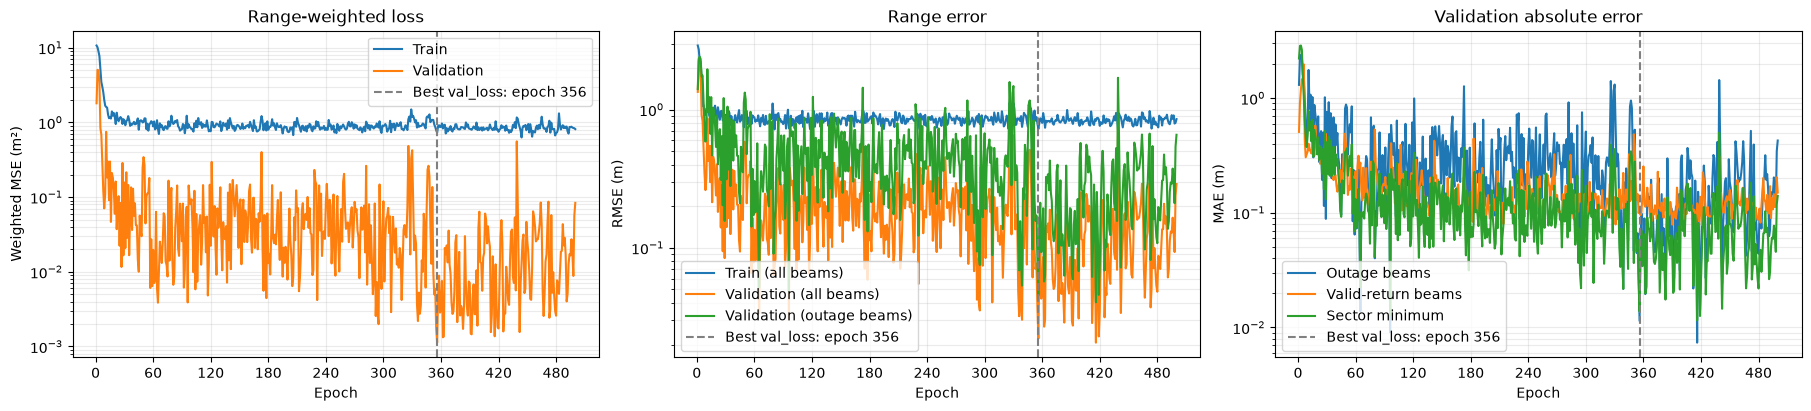

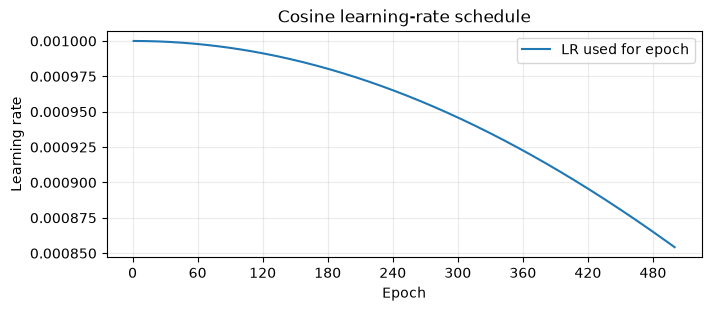

In [23]:
plot_run_history(run_dir, show=True)

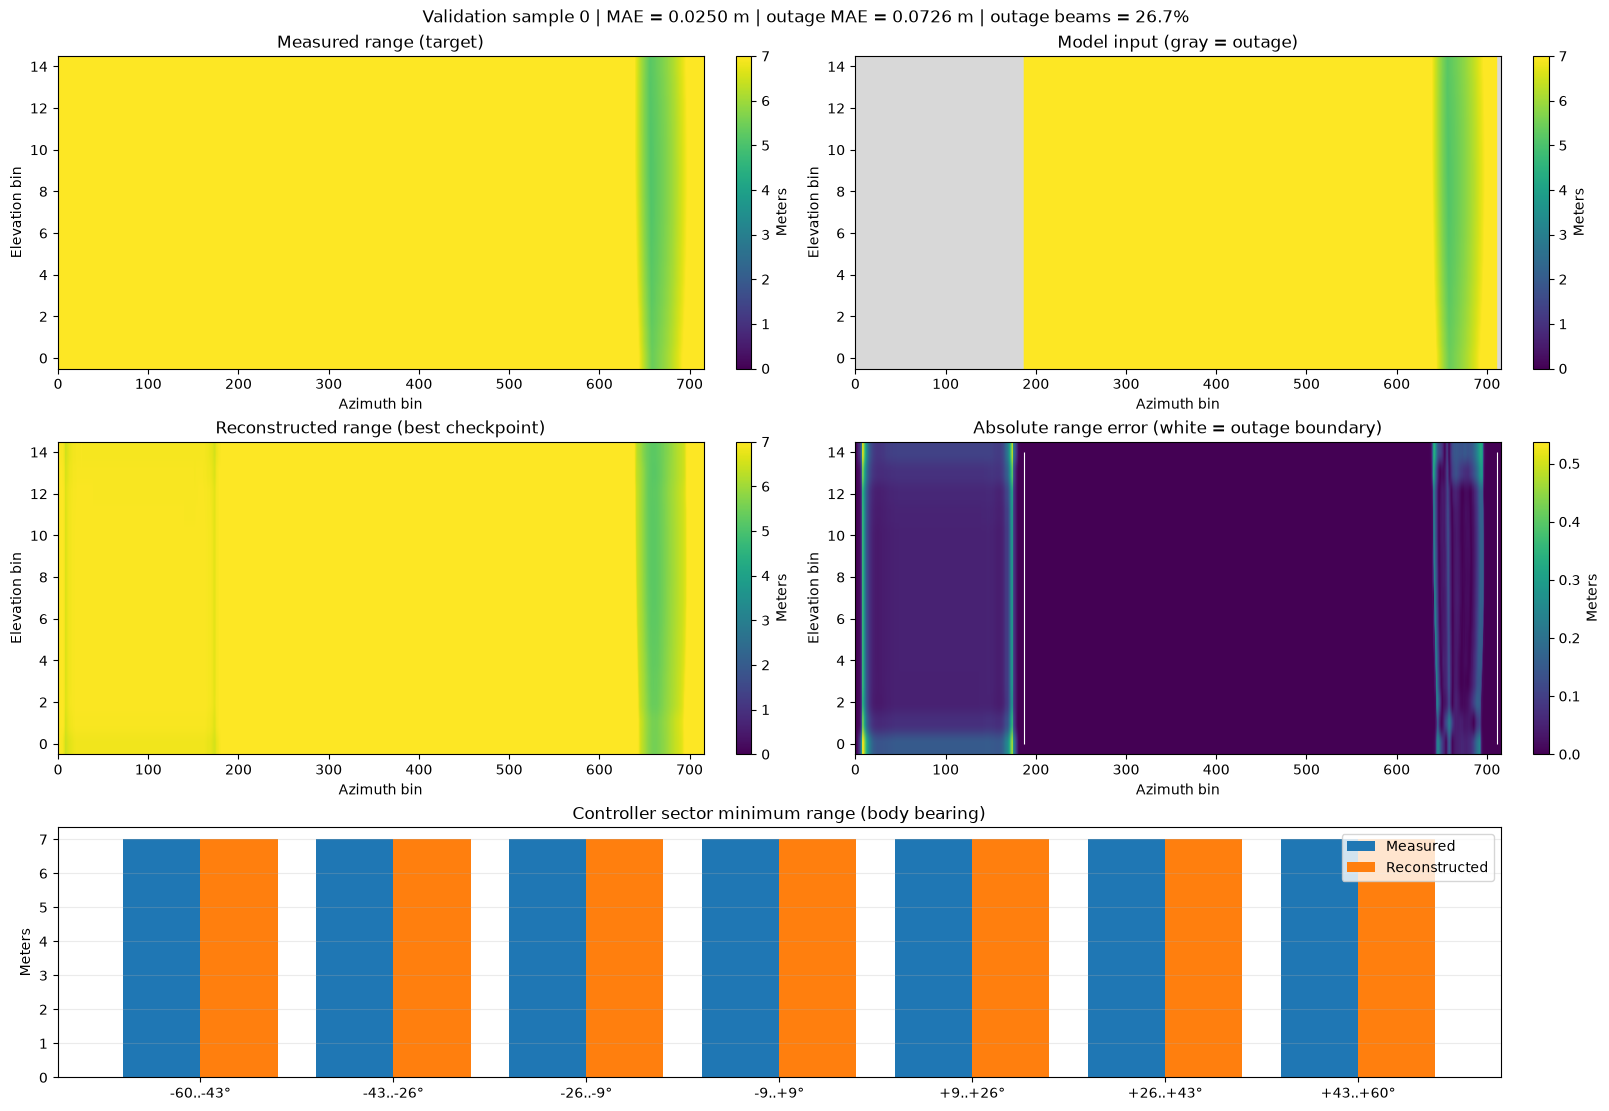

In [24]:
plot_validation_example(model, val_dataset, run_dir, show=True)